# 2. BBMR — IN-SAMPLE PARAMETER STABILITY & PLATEAU CHECK

Strict in-sample only. The two structural axes are:
- **ADX threshold** (regime filter)
- **Bollinger std** (entry aggressiveness)

Structure:
1. 2D PF/N grid ADX × BB_STD.
2. Plateau check (configured + baseline).
3. 4D filter ablation (4 combos × 2 costs = 8 grids).
4. Interactive 3D plotly surface with floor map (PASS/FAIL/margin).

In [24]:
VARIANT = "v1_us500"
STOP_LIMIT = 0.09

In [25]:
import os, sys, importlib
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import plotly.graph_objects as go
from numpy.lib.stride_tricks import sliding_window_view

def find_upwards(name, start=None, must_be_dir=True):
    here = (start or Path.cwd()).resolve()
    for base in (here, *here.parents):
        target = base / name
        if target.is_dir() if must_be_dir else target.exists(): return base
    raise FileNotFoundError(f"Could not find '{name}' from {here}")

EDGE_DIR    = find_upwards('variants')
utils_path  = str(find_upwards('utils') / 'utils')
engine_path = str(EDGE_DIR); engine_dir = str(EDGE_DIR / 'bbmr_engine')
for p in (utils_path, engine_path, engine_dir):
    if p not in sys.path: sys.path.insert(0, p)

from robustness import grid_search, plateau_check, plot_grid
import bbmr_engine as eng
import variant_config
from variant_config import load_variant, save_json

importlib.reload(eng)
variant_config.EDGE_DIR = EDGE_DIR

cfg         = load_variant(VARIANT)
eng.set_engine_defaults(**cfg.get("engine_defaults", {}))
RUN_DIR     = cfg["run_dir"]
TICKER      = cfg["instrument"]["ticker"]
DATA_START  = cfg["instrument"]["start"]
OOS_START   = cfg["oos_start_ts"]

BB_LEN          = cfg["params"]["bb_len"]
BB_STD          = cfg["params"]["bb_std"]
ADX_THR         = cfg["params"]["adx_thr"]
SMA_LEN         = cfg["params"]["sma_len"]
REJECTION_RATIO = cfg["params"]["rejection_ratio"]
MAX_BARS        = cfg["params"]["max_bars"]
ATR_STOP_MULT   = cfg["params"]["atr_stop_mult"]
SLIP_BPS        = cfg["params"]["slip_bps_per_side"]

ADX_VALUES    = cfg["grid"]["adx_values"]
BB_STD_VALUES = cfg["grid"]["bb_std_values"]

print(f"Variant: {cfg['id']} | {TICKER}")
print(f"  BB({BB_LEN},{BB_STD}) ADX<{ADX_THR} SMA({SMA_LEN}) reject>={REJECTION_RATIO} max_bars={MAX_BARS}")
print(f"  Grid: ADX {ADX_VALUES} × BB_STD {BB_STD_VALUES}")

df_raw = eng.load_data(TICKER, start=DATA_START)
common_start = eng.prepare(df_raw, sma_len=SMA_LEN, bb_len=BB_LEN, bb_std=max(BB_STD_VALUES)).index[0]
df_full_prep = eng.prepare(df_raw, sma_len=SMA_LEN, bb_len=BB_LEN, bb_std=BB_STD)
df_full_prep = df_full_prep[df_full_prep.index >= common_start]
is_end_date = df_full_prep.index[df_full_prep.index < OOS_START][-1]
n_is = int((df_full_prep.index <= is_end_date).sum())
print(f"Strict IS range: {df_full_prep.index.min():%Y-%m-%d} to {is_end_date:%Y-%m-%d} | {n_is:,} bars")

Variant: BBMR.us500.m30 | us500
  BB(20,2.0) ADX<25.0 SMA(200) reject>=0.5 max_bars=15
  Grid: ADX [10.0, 15.0, 20.0, 25.0, 30.0, 35.0, 40.0] × BB_STD [1.25, 1.5, 1.75, 2.0, 2.25, 2.5, 2.75]
Strict IS range: 2013-10-22 to 2018-09-21 | 1,238 bars


## 2. 2D PARAMETER GRID (ADX × BB_STD)

In [26]:
is_dfs = {}
for s in BB_STD_VALUES:
    prep = eng.prepare(df_raw, sma_len=SMA_LEN, bb_len=BB_LEN, bb_std=s)
    prep = prep[prep.index >= common_start]
    is_dfs[s] = prep[prep.index <= is_end_date].copy()

assert len({(d.index[0], d.index[-1], len(d)) for d in is_dfs.values()}) == 1, "Date mismatch"

def _kw(s, **over):
    kw = dict(bb_len=BB_LEN, bb_std=s, adx_thr=ADX_THR, sma_len=SMA_LEN,
              rejection_ratio=REJECTION_RATIO, max_bars=MAX_BARS,
              atr_stop_mult=ATR_STOP_MULT, slip_bps_per_side=SLIP_BPS)
    kw.update(over); return kw

def evaluate(adx_thr, bb_std):
    t = eng.run_bbmr_backtest(is_dfs[bb_std], **_kw(bb_std, adx_thr=adx_thr))
    if len(t) == 0: return (0.0, 0)
    p = t['pnl'].values; g, l = p[p>0].sum(), -p[p<0].sum()
    pf = float(g/l) if l > 0 else np.inf
    return (pf, int(len(t)))

pf_grid, n_grid = grid_search(evaluate, ADX_VALUES, BB_STD_VALUES)
print("=" * 70); print("IN-SAMPLE PROFIT FACTOR GRID (ADX × BB_STD)"); print("=" * 70)
display(pf_grid.round(3))
print("\nIN-SAMPLE TRADE COUNT GRID (N)")
display(n_grid.astype(int))

IN-SAMPLE PROFIT FACTOR GRID (ADX × BB_STD)


,1.25,1.50,1.75,2.00,2.25,2.50,2.75
10.0,inf,inf,0.000,0.000,0.000,0.000,0.000
15.0,1.517,2.329,2.037,1.555,1.684,0.862,1.154
20.0,1.815,1.951,2.777,2.151,1.927,0.842,0.635
25.0,1.688,1.808,2.242,1.685,1.407,1.281,1.252
30.0,1.635,2.044,2.759,2.062,1.660,1.405,1.487
35.0,1.713,2.098,2.735,2.131,1.734,1.348,1.379
40.0,1.713,2.098,2.735,2.131,1.734,1.348,1.379



IN-SAMPLE TRADE COUNT GRID (N)


,1.25,1.50,1.75,2.00,2.25,2.50,2.75
10.0,1,1,0,0,0,0,0
15.0,15,12,10,8,7,5,3
20.0,33,28,22,18,13,8,5
25.0,42,37,31,27,20,14,8
30.0,46,41,35,30,22,15,9
35.0,49,44,38,33,23,15,9
40.0,49,44,38,33,23,15,9


## 3. PARAMETER PLATEAU & ANTI-CLIFF

PLATEAU — Configured (ADX=25.0, BB_STD=2.0)
  center_pf                : 1.6845837482272104
  plateau                  : False
  worst_neighbor_drop_pct  : 16.48856529428847
  anticliff                : True
  passed                   : False
  pct_cells_pf_ok          : 0.7755102040816326
  best_cell                : (np.float64(10.0), np.float64(1.25))
  best_pf                  : inf
  edge_of_grid             : False
Verdict: FAILED


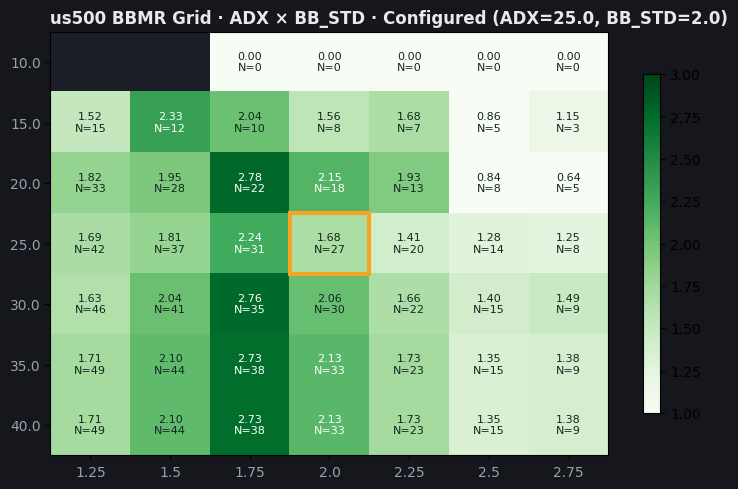

In [27]:
CHOSEN_POINTS = {f"Configured (ADX={ADX_THR}, BB_STD={BB_STD})": (float(ADX_THR), float(BB_STD))}
if (float(ADX_THR), float(BB_STD)) != (25.0, 2.0):
    CHOSEN_POINTS["Baseline (25, 2.0)"] = (25.0, 2.0)

checks = {}
for label, pt in CHOSEN_POINTS.items():
    chk = plateau_check(pf_grid, n_grid, chosen=pt, pf_min=1.3, n_min=30, max_drop_pct=30.0)
    checks[label] = chk
    print("=" * 70); print(f"PLATEAU — {label}"); print("=" * 70)
    for k, v in chk.items(): print(f"  {k:<25}: {v}")
    print(f"Verdict: {'PASSED' if chk['passed'] else 'FAILED'}")
    plot_grid(pf_grid, n_grid, chosen=pt,
              title=f"{TICKER} BBMR Grid · ADX × BB_STD · {label}",
              vmin=1.0, vmax=3.0)

## 4. 4D FILTER ABLATION (4 combos × 2 cost levels = 8 grids)

In [28]:
FILTER_COMBOS = [
    {"adx_thr": ADX_THR, "rejection_ratio": REJECTION_RATIO, "label": "Full BBMR"},
    {"adx_thr": ADX_THR, "rejection_ratio": 0.0,             "label": "No rejection"},
    {"adx_thr": 100.0,   "rejection_ratio": REJECTION_RATIO, "label": "No ADX"},
    {"adx_thr": 100.0,   "rejection_ratio": 0.0,             "label": "No filters"},
]
COSTS = [(SLIP_BPS, f"{SLIP_BPS:g} bps"), (2*SLIP_BPS, f"{2*SLIP_BPS:g} bps")]

all_combos, grid_results = [], {}
for fc in FILTER_COMBOS:
    for slip_val, slip_label in COSTS:
        key = f"{fc['label']} · {slip_label}"
        pf_sub = pd.DataFrame(index=ADX_VALUES, columns=BB_STD_VALUES, dtype=float)
        n_sub  = pd.DataFrame(index=ADX_VALUES, columns=BB_STD_VALUES, dtype=int)
        for adx in ADX_VALUES:
            for s in BB_STD_VALUES:
                eff_adx = 100.0 if fc["adx_thr"] == 100.0 else adx
                t = eng.run_bbmr_backtest(is_dfs[s], **_kw(s, adx_thr=eff_adx,
                    rejection_ratio=fc["rejection_ratio"], slip_bps_per_side=slip_val))
                if len(t) > 0:
                    p = t['pnl'].values; g, l = p[p>0].sum(), -p[p<0].sum()
                    pf = float(g/l) if l > 0 else np.inf
                else:
                    pf = 0.0
                pf_sub.loc[adx, s] = pf
                n_sub.loc[adx, s]  = len(t)
                all_combos.append({"filters": fc["label"], "cost": slip_label,
                                   "adx": adx, "bb_std": s, "pf": pf, "n": len(t)})
        grid_results[key] = pf_sub

combos_df = pd.DataFrame(all_combos)
pfs = combos_df['pf'].values
chosen_pf = combos_df.loc[(combos_df['filters']=='Full BBMR') & (combos_df['cost']==f'{SLIP_BPS:g} bps') &
                          (combos_df['adx']==ADX_THR) & (combos_df['bb_std']==BB_STD), 'pf'].values[0]

print("=" * 70); print("4D FILTER ABLATION RESULTS"); print("=" * 70)
print(f"Total cells: {len(combos_df)}")
print(f"PF >= 1.3 : {(pfs>=1.3).mean()*100:.1f}% ({int((pfs>=1.3).sum())}/{len(pfs)})")
print(f"PF >= 1.0 : {(pfs>=1.0).mean()*100:.1f}% ({int((pfs>=1.0).sum())}/{len(pfs)})")
print(f"min/median/max PF: {pfs.min():.2f} / {np.median(pfs):.2f} / {pfs.max():.2f}")
print(f"Chosen PF (Full BBMR · {SLIP_BPS:g}bps · ADX={ADX_THR} · BB_STD={BB_STD}): {chosen_pf:.3f}")
print(f"Percentile of chosen: {(pfs < chosen_pf).mean()*100:.1f}%")

summ = (combos_df.groupby(["filters","cost"])["pf"]
        .agg(min="min", median="median", max="max", pct_ge_1_3=lambda x: (x>=1.3).mean()*100)
        .round(2))
print("\nPer-scenario summary:"); print(summ.to_string())

4D FILTER ABLATION RESULTS
Total cells: 392
PF >= 1.3 : 72.2% (283/392)
PF >= 1.0 : 93.6% (367/392)
min/median/max PF: 0.00 / 1.52 / inf
Chosen PF (Full BBMR · 5bps · ADX=25.0 · BB_STD=2.0): 1.685
Percentile of chosen: 64.5%

Per-scenario summary:
                      min  median   max  pct_ge_1_3
filters      cost                                  
Full BBMR    10 bps  0.00    1.49   inf       61.22
             5 bps   0.00    1.69   inf       77.55
No ADX       10 bps  1.22    1.50  2.25       71.43
             5 bps   1.37    1.68  2.50      100.00
No filters   10 bps  1.14    1.45  1.98       57.14
             5 bps   1.29    1.60  2.19       85.71
No rejection 10 bps  0.00    1.30   inf       51.02
             5 bps   0.00    1.50   inf       73.47


## 5. INTERACTIVE 3D PROFIT FACTOR SURFACE

Height = in-sample PF. Floor map + markers = headroom to the hard limit on the full period.

In [29]:
LIMIT      = STOP_LIMIT
LIMIT_PCT  = LIMIT*100
STAGE_DAYS = 252
GATE       = "stage"

RAW_FULL  = df_raw
full_dfs  = {int(s*100): eng.prepare(RAW_FULL, sma_len=SMA_LEN, bb_len=BB_LEN, bb_std=s)
             for s in BB_STD_VALUES}

n_grids, dd_grids, st_grids = {}, {}, {}
for fc in FILTER_COMBOS:
    for slip_val, slip_label in COSTS:
        key = f"{fc['label']} · {slip_label}"
        n_sub  = pd.DataFrame(index=ADX_VALUES, columns=BB_STD_VALUES, dtype=float)
        dd_sub = pd.DataFrame(index=ADX_VALUES, columns=BB_STD_VALUES, dtype=float)
        st_sub = pd.DataFrame(index=ADX_VALUES, columns=BB_STD_VALUES, dtype=float)
        for adx in ADX_VALUES:
            for s in BB_STD_VALUES:
                d_full = full_dfs[int(s*100)]
                eff_adx = 100.0 if fc["adx_thr"] == 100.0 else adx
                t = eng.run_bbmr_backtest(d_full, **_kw(s, adx_thr=eff_adx,
                    rejection_ratio=fc["rejection_ratio"], slip_bps_per_side=slip_val))
                n_sub.loc[adx, s] = len(t)
                if len(t) > 0:
                    ret = eng.daily_returns(d_full, t, sizing="atr").astype(float)
                    eq = (1.0 + ret).cumprod()
                    dd_sub.loc[adx, s] = 100.0 * float((eq/eq.cummax() - 1.0).min())
                    if len(ret) >= STAGE_DAYS:
                        w = sliding_window_view(ret.values, STAGE_DAYS)
                        st_sub.loc[adx, s] = 100.0 * float(np.cumprod(1+w, axis=1).min() - 1.0)
        n_grids[key], dd_grids[key], st_grids[key] = n_sub, dd_sub, st_sub

colorscale  = [[0.00,"#b5452f"],[0.25,"#e8a46a"],[0.50,"#f4e79a"],[0.75,"#8fd19e"],[1.00,"#2f7d55"]]
margin_scale= [[0.00,"#b5452f"],[0.45,"#e8704f"],[0.50,"#f5a524"],[0.55,"#8fd19e"],[1.00,"#34d399"]]
keys = list(grid_results.keys())

def _gate(k):
    dd_, st_ = dd_grids[k].astype(float), st_grids[k].astype(float)
    return st_.fillna(dd_) if GATE=="stage" else dd_

amax = max(float(np.nanmax(np.abs(_gate(k).values + LIMIT_PCT))) for k in keys); amax=max(amax,1.0)
pf_all = [grid_results[k].astype(float).replace(np.inf, np.nan) for k in keys]
z_floor = min(1.0, float(np.nanmin([np.nanmin(p.values) for p in pf_all]))) - 0.35
z_top   = float(np.nanmax([np.nanmax(p.values) for p in pf_all])) + 0.25

TPS = 6
fig = go.Figure(); titles = []
for i, key in enumerate(keys):
    pf = grid_results[key].astype(float).replace(np.inf, np.nan)
    dd = dd_grids[key].astype(float).reindex(index=pf.index, columns=pf.columns)
    st = st_grids[key].astype(float).reindex(index=pf.index, columns=pf.columns)
    n_ = n_grids[key].astype(float).reindex(index=pf.index, columns=pf.columns)
    g  = _gate(key).reindex(index=pf.index, columns=pf.columns)
    margin = g + LIMIT_PCT
    ok = (g >= -LIMIT_PCT) & g.notna(); bad = (g < -LIMIT_PCT) & g.notna()
    verdict = np.where(ok.values,"PASS", np.where(bad.values,"FAIL","n/a"))
    n_ok, n_tot = int(ok.values.sum()), int(g.notna().values.sum())

    cd = np.dstack([n_.values, dd.values, margin.values, st.values])
    fig.add_trace(go.Surface(
        x=list(pf.columns), y=list(pf.index), z=pf.values, customdata=cd, text=verdict,
        colorscale=colorscale, cmin=1.0, cmax=3.0,
        colorbar=dict(title="PF (IS)", len=0.42, y=0.80, x=0.93, thickness=14),
        hovertemplate=("BB_STD %{x}<br>ADX< %{y}<br>PF %{z:.2f}<br>Trades %{customdata[0]:.0f}"
                       "<br>MaxDD %{customdata[1]:.1f}%<br>Worst stage %{customdata[3]:.1f}%"
                       f"<br>Limit -{LIMIT_PCT:.0f}%: " + "%{text} (%{customdata[2]:+.1f} pp)<extra></extra>"),
        visible=(i==0)))
    fig.add_trace(go.Surface(
        x=list(pf.columns), y=list(pf.index), z=np.full(pf.shape, z_floor),
        surfacecolor=margin.values, customdata=cd, text=verdict,
        colorscale=margin_scale, cmin=-amax, cmax=amax, opacity=0.95,
        colorbar=dict(title=f"Margin<br>to -{LIMIT_PCT:.0f}%", len=0.42, y=0.30, x=0.93, thickness=14),
        lighting=dict(ambient=1, diffuse=0, specular=0),
        hovertemplate=("FLOOR · BB_STD %{x} · ADX< %{y}<br>MaxDD %{customdata[1]:.1f}%"
                       "<br>Worst stage %{customdata[3]:.1f}%<br>" +
                       f"Limit -{LIMIT_PCT:.0f}%: " + "%{text} (%{customdata[2]:+.1f} pp)<extra></extra>"),
        visible=(i==0)))
    X, Y = np.meshgrid(list(pf.columns), list(pf.index))
    for mask, nm, col, sym in ((ok,"Passes limit","#34d399","diamond"),(bad,"Breaches","#f87171","x")):
        m = (mask.values & pf.notna().values)
        fig.add_trace(go.Scatter3d(
            x=X[m], y=Y[m], z=pf.values[m]+0.04, mode="markers", name=nm,
            marker=dict(size=4, color=col, symbol=sym, line=dict(width=0)),
            showlegend=True, visible=(i==0)))
    c_adx, c_std = float(ADX_THR), float(BB_STD)
    c_dd = float(g.loc[c_adx, c_std]) if pd.notna(g.loc[c_adx, c_std]) else np.nan
    c_ok = (not np.isnan(c_dd)) and c_dd >= -LIMIT_PCT
    fig.add_trace(go.Scatter3d(
        x=[c_std], y=[c_adx], z=[float(pf.loc[c_adx, c_std])+0.08],
        mode="markers+text", text=[f"chosen {'✓' if c_ok else '✗'}"],
        textposition="top center", textfont=dict(color="#34d399" if c_ok else "#f87171", size=13),
        marker=dict(size=7, color="white", line=dict(color="#34d399" if c_ok else "#f87171", width=3)),
        showlegend=False, visible=(i==0)))

    titles.append(f"{cfg['id']} · PF in-sample · {n_ok}/{n_tot} cells within -{LIMIT_PCT:.0f}%")

PAD=" "; buttons=[]
for i, key in enumerate(keys):
    vis=[False]*(TPS*len(keys))
    for j in range(TPS): vis[TPS*i+j]=True
    buttons.append(dict(label=f"{PAD}{key}{PAD}", method="update",
                        args=[{"visible":vis},{"title.text":titles[i]}]))

fig.update_layout(
    template="plotly_dark", paper_bgcolor="#15171c", height=700,
    title=dict(text=titles[0], x=0.02),
    scene=dict(xaxis_title="BB std", yaxis_title="ADX threshold",
               zaxis_title="Profit Factor", zaxis=dict(range=[z_floor, z_top]),
               aspectmode="manual", aspectratio=dict(x=1.5,y=1.0,z=0.8),
               camera=dict(eye=dict(x=1.6,y=1.6,z=0.9))),
    updatemenus=[dict(type="buttons", direction="right", x=0.0, xanchor="left",
                      y=1.12, yanchor="top", active=0, buttons=buttons,
                      bgcolor="#9fb3c8", font=dict(color="#15171c", size=12))],
    margin=dict(l=0, r=0, t=90, b=30))
fig.write_html(Path(RUN_DIR) / "02_pf_surface.html", include_plotlyjs="cdn")
fig.show()

## 6. CONCLUSIONS & 7. OPTIMIZATION PARITY

In [30]:
print("=" * 70); print("CONCLUSIONS"); print("=" * 70)
for label, chk in checks.items():
    print(f"{label}: center PF {chk['center_pf']:.3f} | worst nb drop -{chk['worst_neighbor_drop_pct']:.1f}% | "
          f"plateau {'PASS' if chk['plateau'] else 'FAIL'} | anticliff {'PASS' if chk['anticliff'] else 'FAIL'}")
print(f"\n4D: {len(combos_df)} cells | PF≥1.3 in {(pfs>=1.3).mean()*100:.1f}% | PF≥1.0 in {(pfs>=1.0).mean()*100:.1f}%")

save_json(cfg, "02_optimization.json", {
    "variant": cfg["id"], "ticker": TICKER,
    "params_tested": {"adx_thr": ADX_THR, "bb_std": BB_STD, "bb_len": BB_LEN,
                      "sma_len": SMA_LEN, "rejection_ratio": REJECTION_RATIO,
                      "max_bars": MAX_BARS, "atr_stop_mult": ATR_STOP_MULT},
    "is_end_date": str(is_end_date.date()),
    "n_is_bars": int(n_is),
    "plateau_checks": checks,
    "grid_4d": {"n_combinations": int(len(combos_df)),
                "pct_pf_ge_1_3": float((pfs>=1.3).mean()*100),
                "pct_pf_ge_1_0": float((pfs>=1.0).mean()*100),
                "min_pf": float(pfs.min()), "median_pf": float(np.median(pfs)),
                "max_pf": float(pfs.max()), "chosen_pf": float(chosen_pf)},
})

# Optimization parity
BASE_VARIANT = None
if BASE_VARIANT:
    cb = load_variant(BASE_VARIANT)
    rb_all = eng.load_data(cb["instrument"]["ticker"], start=DATA_START, source="yahoo")
    base_common = eng.prepare(rb_all, sma_len=SMA_LEN, bb_len=BB_LEN, bb_std=max(BB_STD_VALUES)).index[0]
    start_b = max(common_start, base_common)
    is_dfs_b = {}
    for s in BB_STD_VALUES:
        prep = eng.prepare(rb_all, sma_len=SMA_LEN, bb_len=BB_LEN, bb_std=s)
        is_dfs_b[s] = prep[(prep.index >= start_b) & (prep.index <= is_end_date)].copy()

    def evaluate_base(adx, s):
        t = eng.run_bbmr_backtest(is_dfs_b[s], **_kw(s, adx_thr=adx))
        if len(t) == 0: return (0.0, 0)
        p = t["pnl"].values; g, l = p[p>0].sum(), -p[p<0].sum()
        return (float(g/l) if l > 0 else np.inf, int(len(t)))

    pf_b, n_b = grid_search(evaluate_base, ADX_VALUES, BB_STD_VALUES)
    pf_v = pf_grid.replace(np.inf, np.nan).astype(float)
    pf_bc = pf_b.replace(np.inf, np.nan).astype(float)
    both = pd.concat([pf_v.stack(), pf_bc.stack()], axis=1, keys=["v","b"]).dropna()
    print(f"Grid correlation: {both['v'].corr(both['b']):.3f}")
    print(f"Median PF variant/base: {both['v'].median():.3f} / {both['b'].median():.3f}")

CONCLUSIONS
Configured (ADX=25.0, BB_STD=2.0): center PF 1.685 | worst nb drop -16.5% | plateau FAIL | anticliff PASS

4D: 392 cells | PF≥1.3 in 72.2% | PF≥1.0 in 93.6%
Saved: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/notebooks/BBMR/runs/v1_us500/02_optimization.json
